# Patrón de subestimación de finales de 2024 y 2025

> **Diagnóstico, no modificación**: el modelo no se cambia por este análisis (regla 3 de la entrega final).

- Datos: solo `cargar_entrenamiento("central")` (febrero 2019 – julio 2025). La prueba no se toca.
- Modelo: el Ridge preliminar de la Entrega 2 (predictores `_rez1`, alpha = 1000), la misma especificación que vio la profesora.
- **Residuo = observado − predicho**: positivo significa que el modelo se queda corto (subestima).

In [2]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone

from src.config import DEPARTAMENTOS, LINEAS, OBJETIVO, PREDICTORES_REZ1
from src.datos.cargar import cargar_entrenamiento
from src.evaluacion.agregacion import agregar_nacional
from src.evaluacion.metricas import mape
from src.evaluacion.particion import CVTemporalPorMes
from src.evaluacion.validar import buscar_hiperparametros, mape_cv_ganador
from src.figuras import aplicar_estilo, guardar_figura
from src.modelos.candidatos import construir_candidato, prefijo
from src.modelos.pipeline import ORDEN_FILAS

aplicar_estilo()
ALPHA_E2 = 1000.0

## 1. Residuos fuera de muestra (validación cruzada) y de ajuste

In [3]:
df = cargar_entrenamiento("central").sort_values(ORDEN_FILAS, kind="stable").reset_index(drop=True)
y = df[OBJETIVO].to_numpy(dtype=float)
ridge, _ = construir_candidato("ridge")
ridge.set_params(**{f"{prefijo()}alpha": ALPHA_E2})

# Fuera de muestra: cada mes de validación lo predice un modelo que no lo vio
df["oof"] = np.nan
for entrena, valida in CVTemporalPorMes().split(df):
    modelo = clone(ridge).fit(df.iloc[entrena], y[entrena])
    df.loc[df.index[valida], "oof"] = modelo.predict(df.iloc[valida])

# Ajuste: modelo entrenado con todo el periodo (residuos dentro de muestra)
df["ajuste"] = clone(ridge).fit(df, y).predict(df)

def nacional(datos, columnas):
    out = pd.DataFrame({c: agregar_nacional(datos, c) for c in columnas})
    out.index = pd.to_datetime(out.index)
    return out

val = nacional(df.dropna(subset=["oof"]), [OBJETIVO, "oof"])
val["residuo"] = val[OBJETIVO] - val["oof"]
aju = nacional(df, [OBJETIVO, "ajuste"])
aju["residuo"] = aju[OBJETIVO] - aju["ajuste"]

# Desde cuándo los residuos fuera de muestra son positivos sin interrupción
signo = (val["residuo"] > 0).to_numpy()
inicio_racha = val.index[len(signo) - np.argmin(signo[::-1])] if not signo.all() else val.index[0]
ult12 = val.loc[val.index[-12]:]
print(f"MAPE de validación (comprobación): {mape(val[OBJETIVO], val['oof']):.2f} %")
print(f"Residuos positivos sin interrupción desde: {inicio_racha:%Y-%m}")
print(f"Últimos 12 meses de validación: {(ult12['residuo'] > 0).sum()} de 12 positivos, "
      f"residuo medio {ult12['residuo'].mean():+.1f} puntos")
val.round(1).tail(12)

MAPE de validación (comprobación): 9.08 %
Residuos positivos sin interrupción desde: 2024-11
Últimos 12 meses de validación: 10 de 12 positivos, residuo medio +21.3 puntos


,indice_ventas_real,oof,residuo
fecha,,,
2024-08-01,138.4,118.2,20.1
2024-09-01,120.0,124.3,-4.4
2024-10-01,123.7,123.8,-0.1
2024-11-01,150.7,121.5,29.2
2024-12-01,152.6,134.6,17.9
2025-01-01,146.1,117.7,28.4
2025-02-01,132.5,117.2,15.3
2025-03-01,144.4,122.7,21.7
2025-04-01,129.2,109.5,19.7


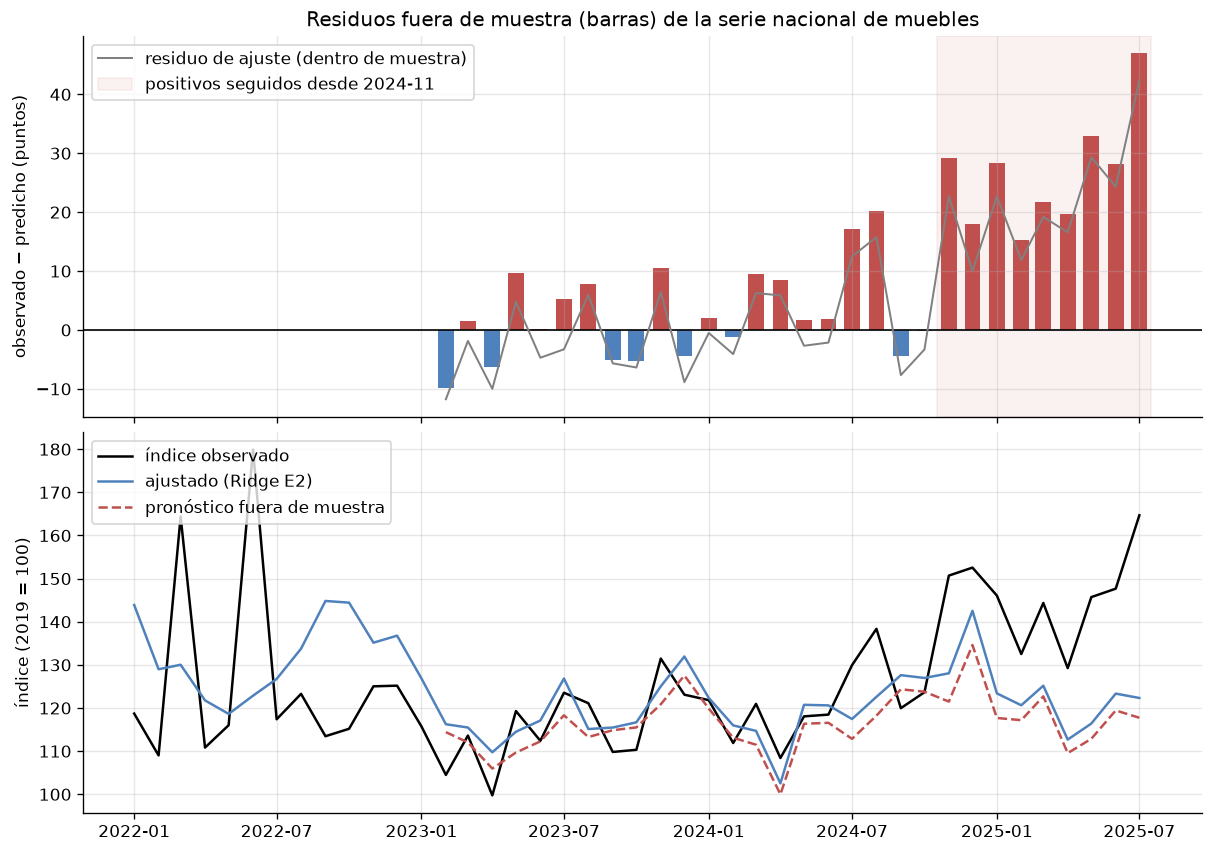

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, layout="constrained")
ax1.axhline(0, color="black", lw=1)
ax1.bar(val.index, val["residuo"], width=20,
        color=np.where(val["residuo"] > 0, "#c0504d", "#4f81bd"))
ax1.plot(aju.loc["2023-02":].index, aju.loc["2023-02":, "residuo"], color="gray", lw=1.2,
         label="residuo de ajuste (dentro de muestra)")
ax1.axvspan(inicio_racha - pd.Timedelta(days=15), val.index[-1] + pd.Timedelta(days=15),
            color="#c0504d", alpha=0.08, label=f"positivos seguidos desde {inicio_racha:%Y-%m}")
ax1.set_ylabel("observado − predicho (puntos)")
ax1.set_title("Residuos fuera de muestra (barras) de la serie nacional de muebles")
ax1.legend(loc="upper left")

serie = aju.loc["2022-01":]
ax2.plot(serie.index, serie[OBJETIVO], color="black", label="índice observado")
ax2.plot(serie.index, serie["ajuste"], color="#4f81bd", label="ajustado (Ridge E2)")
ax2.plot(val.index, val["oof"], color="#c0504d", ls="--", label="pronóstico fuera de muestra")
ax2.set_ylabel("índice (2019 = 100)")
ax2.legend(loc="upper left")
guardar_figura(fig, "fig_errores_residuos")

## 2. Preguntas clave

### 2.1 ¿Cambió la tendencia del mercado?

In [5]:
desde = aju.loc["2023-01":]
pend_aju = np.polyfit(np.arange(len(desde)), desde["residuo"], 1)[0]
v23 = val.loc["2023-01":]
pend_val = np.polyfit(np.arange(len(v23)), v23["residuo"], 1)[0]
crec = aju[OBJETIVO].groupby(aju.index.year).mean()
print(f"Pendiente del residuo de ajuste desde 2023: {pend_aju:+.2f} puntos por mes")
print(f"Pendiente del residuo fuera de muestra desde 2023: {pend_val:+.2f} puntos por mes")
print("Índice nacional observado, promedio anual:")
print(crec.round(1).to_string())

Pendiente del residuo de ajuste desde 2023: +1.17 puntos por mes
Pendiente del residuo fuera de muestra desde 2023: +1.21 puntos por mes
Índice nacional observado, promedio anual:
fecha
2019    100.9
2020    109.1
2021    125.6
2022    126.5
2023    115.4
2024    126.2
2025    144.3


### 2.2 ¿Los predictores rezagados no capturan el crecimiento?

In [6]:
nac_pred = df[df["linea_codigo"] == 8].groupby("fecha")[PREDICTORES_REZ1].first()
nac_pred.index = pd.to_datetime(nac_pred.index)
nac_pred["indice"] = aju[OBJETIVO]
z = nac_pred.loc["2022-01":]
z = (z - z.mean()) / z.std()
print("Correlación de cada predictor con el índice, 2022–2025:")
print(z.corr()["indice"].drop("indice").round(2).to_string())
print("\nPromedio anual estandarizado:")
print(z.groupby(z.index.year).mean().round(2).to_string())

Correlación de cada predictor con el índice, 2022–2025:
icc_rez1                                0.44
inflacion_anual_rez1                   -0.53
tasa_consumo_rez1                      -0.54
importaciones_muebles_usd_miles_rez1    0.17
area_vivienda_m2_rez1                  -0.07

Promedio anual estandarizado:
       icc_rez1  inflacion_anual_rez1  tasa_consumo_rez1  importaciones_muebles_usd_miles_rez1  area_vivienda_m2_rez1  indice
fecha                                                                                                                        
2022       0.10                  0.25              -0.39                                  0.67                   0.84    0.02
2023      -1.02                  1.14               1.36                                 -0.79                  -0.27   -0.62
2024       0.29                 -0.64              -0.30                                  0.05                  -0.45   -0.00
2025       1.08                 -1.28              -1.15  

### 2.3 ¿Hace falta una tendencia explícita? (solo diagnóstico: no se adopta)

In [7]:
fechas = pd.to_datetime(df["fecha"])
df["tendencia"] = (fechas.dt.year - 2019) * 12 + fechas.dt.month - 1

def diagnostico(predictores):
    busqueda = buscar_hiperparametros("ridge", df, predictores)
    mapes = mape_cv_ganador(busqueda)
    residuos = []
    for entrena, valida in CVTemporalPorMes().split(df):
        m = clone(busqueda.best_estimator_).fit(df.iloc[entrena], y[entrena])
        d = df.iloc[valida][["fecha", "departamento", "linea_codigo", OBJETIVO]].copy()
        d["p"] = m.predict(df.iloc[valida])
        residuos.append(agregar_nacional(d, OBJETIVO) - agregar_nacional(d, "p"))
    r = pd.concat(residuos)
    return {"alpha": busqueda.best_params_[f"{prefijo()}alpha"],
            "MAPE medio": mapes.mean(), "desv. folds": mapes.std(ddof=1),
            "sesgo medio": r.mean(), "sesgo últimos 12": r.iloc[-12:].mean(),
            "MAPE por fold": np.round(mapes, 2)}

tabla_tend = pd.DataFrame({
    "Ridge E2": diagnostico(PREDICTORES_REZ1),
    "Ridge E2 + tendencia": diagnostico([*PREDICTORES_REZ1, "tendencia"]),
}).T
tabla_tend

,alpha,MAPE medio,desv. folds,sesgo medio,sesgo últimos 12,MAPE por fold
Ridge E2,1000.0,9.079339,6.03606,9.980359,21.321867,"[4.92, 4.84, 5.49, 11.48, 18.66]"
Ridge E2 + tendencia,1000.0,8.299779,1.178744,-4.55888,3.869201,"[8.33, 8.89, 9.77, 7.91, 6.6]"


### 2.4 ¿Cambio estructural pospandemia?

In [8]:
periodos = {"2019": ("2019-02", "2019-12"), "2021–2023": ("2021-01", "2023-12"),
            "2024–2025": ("2024-01", "2025-07")}
filas = []
for nombre, (a, b) in periodos.items():
    s = aju.loc[a:b]
    filas.append({"periodo": nombre, "residuo medio (puntos)": s["residuo"].mean(),
                  "residuo medio (% del observado)": 100 * (s["residuo"] / s[OBJETIVO]).mean(),
                  "meses positivos": f"{(s['residuo'] > 0).sum()} de {len(s)}"})
pd.DataFrame(filas).round(2)

,periodo,residuo medio (puntos),residuo medio (% del observado),meses positivos
0,2019,-12.34,-13.02,0 de 11
1,2021–2023,0.11,-1.21,13 de 36
2,2024–2025,11.52,7.84,13 de 19


### 2.5 ¿Alguna línea o departamento concentra el error?

Últimos 12 meses de entrenamiento (agosto 2024 – julio 2025), residuo de ajuste en % del observado.
La diferencia entre **líneas** viene de series observadas (L, DANE); la diferencia entre **departamentos** mezcla el factor regional real (F) con el componente simulado (η), así que solo vale dentro del escenario central.

Residuo medio por línea (promedio de departamentos):
11 · Informatica y telecomunicaciones     41.1
9 · Articulos y utensilios domesticos     15.5
12 · Sonido y video                       14.7
8 · Electrodomesticos y muebles            9.4
15 · Otras mercancias de uso domestico     3.9
10 · Aseo del hogar                        1.1
14 · Ferreteria, vidrios y pinturas      -14.4
4 · Prendas de vestir y textiles         -18.7


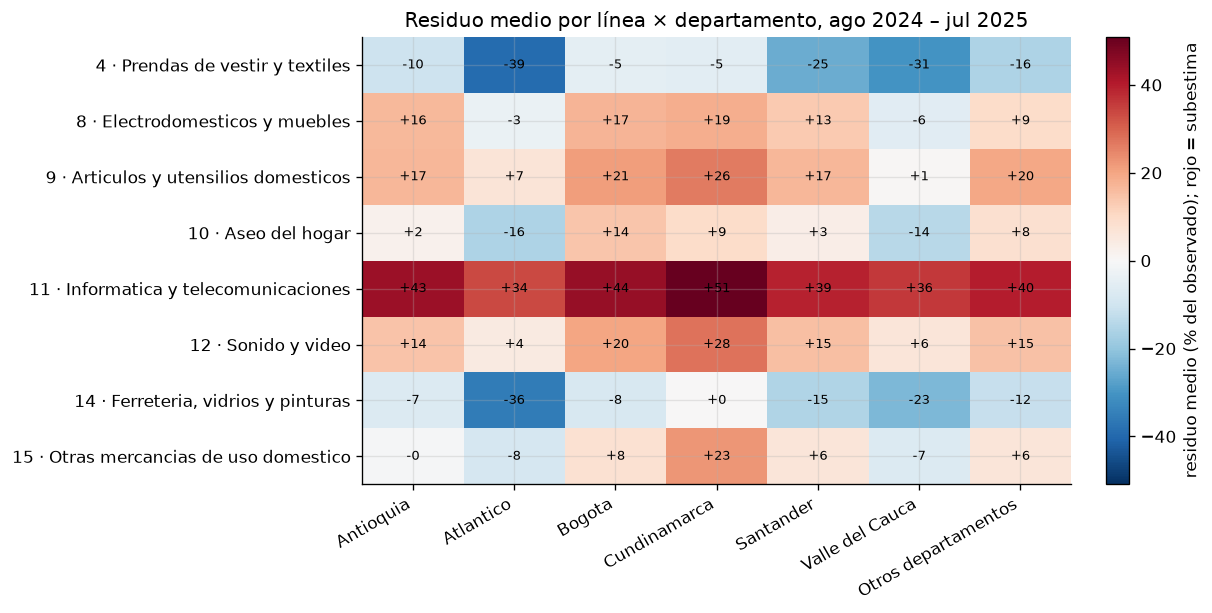

In [9]:
u = df[df["fecha"] >= df["fecha"].max() - pd.DateOffset(months=11)].copy()
u["residuo_pct"] = 100 * (u[OBJETIVO] - u["ajuste"]) / u[OBJETIVO]
mapa = u.pivot_table(index="linea_codigo", columns="departamento", values="residuo_pct")
mapa = mapa[DEPARTAMENTOS]
mapa.index = [f"{c} · {LINEAS[c]}" for c in mapa.index]

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
lim = np.nanmax(np.abs(mapa.to_numpy()))
im = ax.imshow(mapa, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(mapa.shape[1]), mapa.columns, rotation=30, ha="right")
ax.set_yticks(range(mapa.shape[0]), mapa.index)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        ax.text(j, i, f"{mapa.iat[i, j]:+.0f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="residuo medio (% del observado); rojo = subestima")
ax.set_title("Residuo medio por línea × departamento, ago 2024 – jul 2025")
guardar_figura(fig, "fig_errores_mapa_lineas")
print("Residuo medio por línea (promedio de departamentos):")
print(mapa.mean(axis=1).sort_values(ascending=False).round(1).to_string())